# Experiment 11a — GRU Encoder-Decoder with Cross-Attention

This notebook implements a Bidirectional GRU encoder + attention decoder for the 336-hour
operational load forecasting task. It extends exp-7a-seq2seq with three architectural improvements:

1. **Bahdanau cross-attention**: the decoder queries all encoder hidden states at every step, not
   just the final state. Implemented via `nn.MultiheadAttention` (parallelised, avoids the
   step-by-step GRUCell loop).
2. **Shorter lookback (168h)**: reduces vanishing-gradient pressure; a subsequence-crop
   augmentation still exposes the model to 168–336h context during training.
3. **Block-C velocity features**: first backward diff of the top-3 domain covariates
   (`queue_pressure`, `network_pressure`, `shock_risk`) — the only feature block that moved
   WAPE in exp-10a.

Additionally, three data augmentations from the aug/dlinear teammate branch are incorporated:
- **Feature dropout** (p=0.1, covariate columns, training only)
- **Subsequence crop** (random lookback in [168, 336] per batch)
- **Hard-series oversampling** (3× for the worst-20 series)

The notebook runs a **4-variant ablation** (§6) on the GRU base to determine which components
actually help before committing to the full 5-seed CV (§7).

Read `README.md` for joint interpretation with 11b (LSTM) and 11c (blend).

---
## §0. Configuration

In [1]:
from pathlib import Path

# ── Paths ─────────────────────────────────────────────────────────────────────
DATA_DIR   = Path("/kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data")
OUTPUT_DIR = Path("/kaggle/working")
# Local override:
# DATA_DIR   = Path("../data")
# OUTPUT_DIR = Path(".")

TRAIN_PATH     = DATA_DIR / "train.csv"
VAL_INPUT_PATH = DATA_DIR / "validation_input.csv"
VAL_INDEX_PATH = DATA_DIR / "forecast_index_validation.csv"

EXP_ID          = "11a_gru"
OOF_OUT         = OUTPUT_DIR / f"oof_predictions_{EXP_ID}.csv"
VAL_OUT         = OUTPUT_DIR / f"validation_predictions_{EXP_ID}.csv"
ABLATION_OUT    = OUTPUT_DIR / f"ablation_{EXP_ID}.csv"

# ── Reproducibility & CV ──────────────────────────────────────────────────────
SEED         = 42
N_FOLDS      = 3
EVAL_HORIZON = 336

# ── Feature columns ───────────────────────────────────────────────────────────
DOMAIN_FEAT_COLS = [
    "workload_intensity", "demand_forecast", "upstream_quality_forecast",
    "promotion_intensity", "shock_risk", "maintenance_known",
    "unit_reliability_forecast", "queue_pressure_forecast",
    "network_pressure_forecast", "event_load_forecast",
    "service_irregularity_risk_forecast",
]
VELOCITY_COLS = ["queue_pressure_forecast", "network_pressure_forecast", "shock_risk"]
TIME_COLS     = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "doy_sin", "doy_cos", "is_weekend"]

N_DOMAIN = len(DOMAIN_FEAT_COLS)  # 11
N_VELS   = len(VELOCITY_COLS)     # 3
N_TIME   = len(TIME_COLS)         # 7

# ── Seq2seq hyperparameters ────────────────────────────────────────────────────
ENCODER_LOOKBACK = 168
CROP_LOOKBACK_LO = 168
CROP_LOOKBACK_HI = 336

EMBED_DIM    = 16
HIDDEN_DIM   = 128
N_ENC_LAYERS = 2
N_DEC_LAYERS = 1
ATTN_HEADS   = 4
DROPOUT      = 0.2

BATCH_SIZE   = 512   # T4 has plenty of VRAM; larger batches keep GPU busy
N_EPOCHS     = 50
PATIENCE     = 7     # saves ~3 wasted epochs on average
LR           = 1e-3
LR_MIN       = 1e-5
WEIGHT_DECAY = 1e-4
GRAD_CLIP    = 1.0
STRIDE       = 24    # one window per day (was 6); 4× smaller dataset → 4× faster epochs
N_WORKERS    = 4     # parallel data loading; stops GPU idling between batches

N_SEEDS   = 5
SEQ_SEEDS = [42, 7, 13, 99, 1234]

# ── Augmentation ──────────────────────────────────────────────────────────────
FEAT_DROP_P     = 0.1
HARD_SERIES_OVS = 3

HARD_SERIES_IDS = [
    "unit_073", "unit_058", "unit_066", "unit_056", "unit_039",
    "unit_071", "unit_003", "unit_079", "unit_031", "unit_061",
    "unit_012", "unit_027", "unit_034", "unit_048", "unit_051",
    "unit_063", "unit_069", "unit_077", "unit_082", "unit_090",
]

---
## §1. Setup & Data Loading

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.preprocessing import RobustScaler

np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"  GPU: {torch.cuda.get_device_name(0)}")

def wape(y_true, y_pred, eps=1e-8):
    return np.sum(np.abs(np.asarray(y_true) - np.asarray(y_pred))) / \
           (np.sum(np.abs(y_true)) + eps) * 100

train_df  = pd.read_csv(TRAIN_PATH,     parse_dates=["timestamp"])
val_input = pd.read_csv(VAL_INPUT_PATH, parse_dates=["timestamp"])
val_index = pd.read_csv(VAL_INDEX_PATH, parse_dates=["timestamp"])

sid_to_code = {sid: i for i, sid in enumerate(sorted(train_df["series_id"].unique()))}
code_to_sid = {v: k for k, v in sid_to_code.items()}
N_SERIES = len(sid_to_code)

print(f"train_df : {train_df.shape}")
print(f"# series : {N_SERIES}")
print(f"hours/series: {len(train_df) // N_SERIES}")

PyTorch device: cuda
  GPU: Tesla T4
train_df : (414720, 25)
# series : 96
hours/series: 4320


---
## §2. Preprocessing & Sequence Arrays

Builds per-series arrays once; normalization is refit per fold in §5.

**Block-C velocity features** (first backward diff, causal):
- `queue_pressure_velocity = queue_pressure[t] - queue_pressure[t-1]`, with `vel[0] = 0`.
- Same for `network_pressure` and `shock_risk`.
These are the only feature additions from exp-10a that showed a positive signal.

In [3]:
def impute_domain_features(df, cols):
    df = df.sort_values(["series_id", "timestamp"]).copy()
    df[cols] = df.groupby("series_id", group_keys=False)[cols].transform(
        lambda x: x.ffill().bfill()
    )
    return df

def add_time_features(df, time_col="timestamp"):
    df = df.copy()
    t = pd.to_datetime(df[time_col])
    df["hour_sin"]   = np.sin(2 * np.pi * t.dt.hour / 24)
    df["hour_cos"]   = np.cos(2 * np.pi * t.dt.hour / 24)
    df["dow_sin"]    = np.sin(2 * np.pi * t.dt.dayofweek / 7)
    df["dow_cos"]    = np.cos(2 * np.pi * t.dt.dayofweek / 7)
    df["doy_sin"]    = np.sin(2 * np.pi * t.dt.dayofyear / 365)
    df["doy_cos"]    = np.cos(2 * np.pi * t.dt.dayofyear / 365)
    df["is_weekend"] = (t.dt.dayofweek >= 5).astype(float)
    return df

# Preprocess training data
train_df = impute_domain_features(train_df, DOMAIN_FEAT_COLS)
train_df = add_time_features(train_df)
train_df = train_df.sort_values(["series_id", "timestamp"]).reset_index(drop=True)

# Preprocess validation input
val_input = impute_domain_features(val_input, DOMAIN_FEAT_COLS)
val_input = add_time_features(val_input)
val_input = val_input.sort_values(["series_id", "timestamp"]).reset_index(drop=True)

T_PER_SERIES = len(train_df) // N_SERIES
print(f"T_PER_SERIES = {T_PER_SERIES}")

# Build per-series arrays with velocity features
# Each SERIES_ARR[s] has:
#   'cov'  : (T, N_DOMAIN)   — domain covariates
#   'vel'  : (T, N_VELS)     — block-C velocities of top-3 covariates
#   'time' : (T, N_TIME)     — time encodings
#   'tgt'  : (T,)            — target
#   'ts'   : (T,)            — timestamps (for OOF output)

SERIES_ARR = {}
VEL_IDX = [DOMAIN_FEAT_COLS.index(c) for c in VELOCITY_COLS]  # indices in DOMAIN_FEAT_COLS

for s in range(N_SERIES):
    sid = code_to_sid[s]
    g = train_df[train_df["series_id"] == sid].sort_values("timestamp")
    cov  = g[DOMAIN_FEAT_COLS].to_numpy(dtype=np.float32)
    vel  = np.zeros_like(cov[:, VEL_IDX])
    vel[1:] = np.diff(cov[:, VEL_IDX], axis=0)   # causal; vel[0] = 0
    time = g[TIME_COLS].to_numpy(dtype=np.float32)
    tgt  = g["target"].to_numpy(dtype=np.float32)
    ts   = g["timestamp"].to_numpy()
    SERIES_ARR[s] = dict(cov=cov, vel=vel, time=time, tgt=tgt, ts=ts)

# Build per-series future arrays (val_input)
VAL_ARR = {}
for s in range(N_SERIES):
    sid = code_to_sid[s]
    g   = val_input[val_input["series_id"] == sid].sort_values("timestamp")
    # Future velocity: stitch last training step to compute vel[0]
    last_cov = SERIES_ARR[s]["cov"][-1:, VEL_IDX]   # (1, N_VELS)
    fut_cov_vel = g[VELOCITY_COLS].to_numpy(dtype=np.float32)
    fut_stitch  = np.concatenate([last_cov, fut_cov_vel], axis=0)  # (H+1, N_VELS)
    fut_vel     = np.diff(fut_stitch, axis=0)                      # (H, N_VELS)
    VAL_ARR[s]  = dict(
        cov  = g[DOMAIN_FEAT_COLS].to_numpy(dtype=np.float32),
        vel  = fut_vel,
        time = g[TIME_COLS].to_numpy(dtype=np.float32),
        ts   = g["timestamp"].to_numpy(),
    )

print("Series arrays built.")
print(f"Train cov shape for s=0: {SERIES_ARR[0]['cov'].shape}")
print(f"Val   cov shape for s=0: {VAL_ARR[0]['cov'].shape}")

T_PER_SERIES = 4320
Series arrays built.
Train cov shape for s=0: (4320, 11)
Val   cov shape for s=0: (336, 11)


---
## §3. CV Framework

In [4]:
def fold_train_end_idx(k):
    "Last exclusive index of the training slice for fold k."
    end_off = (N_FOLDS - k) * EVAL_HORIZON
    return T_PER_SERIES - end_off

def fold_test_slice(k):
    "(start, end) index of the test window for fold k."
    start = fold_train_end_idx(k)
    return start, start + EVAL_HORIZON

for k in range(N_FOLDS):
    te_start, te_end = fold_test_slice(k)
    print(f"Fold {k}: train=[0..{fold_train_end_idx(k)}), test=[{te_start}..{te_end})")

# Hard-series mask (for oversampling weights)
HARD_CODES = set(sid_to_code.get(s, -1) for s in HARD_SERIES_IDS if s in sid_to_code)
print(f"\nHard series codes tracked: {len(HARD_CODES)} / {N_SERIES}")

Fold 0: train=[0..3312), test=[3312..3648)
Fold 1: train=[0..3648), test=[3648..3984)
Fold 2: train=[0..3984), test=[3984..4320)

Hard series codes tracked: 20 / 96


---
## §4. Dataset and Normalization

In [5]:
def fit_fold_normalizers(k):
    "Per-fold: RobustScaler on covariates, per-series z-score on target."
    end_idx = fold_train_end_idx(k)
    all_cov = np.concatenate([SERIES_ARR[s]["cov"][:end_idx] for s in range(N_SERIES)], axis=0)
    all_vel = np.concatenate([SERIES_ARR[s]["vel"][:end_idx] for s in range(N_SERIES)], axis=0)
    feat_scaler = RobustScaler().fit(all_cov)
    vel_scaler  = RobustScaler().fit(all_vel)
    mu = np.array([SERIES_ARR[s]["tgt"][:end_idx].mean() for s in range(N_SERIES)], dtype=np.float32)
    sd = np.array([max(float(SERIES_ARR[s]["tgt"][:end_idx].std()), 1e-3) for s in range(N_SERIES)], dtype=np.float32)
    return feat_scaler, vel_scaler, mu, sd


class Seq2SeqDataset(Dataset):
    """
    Each sample = (series_id, start_hour) pair giving:
      encoder window : [start .. start+lookback]
      decoder window : [start+lookback .. start+lookback+EVAL_HORIZON]

    Velocity for encoder AND decoder is served from a precomputed normalised array
    (no per-sample sklearn calls in __getitem__).
    """
    def __init__(self, fold_k, feat_scaler, vel_scaler, mu, sd,
                 use_aug=False, crop_lo=168, crop_hi=336,
                 feat_drop_p=0.0, oversample_factor=1,
                 end_idx_override=None):
        self.feat_scaler = feat_scaler
        self.vel_scaler  = vel_scaler
        self.mu, self.sd = mu, sd
        self.use_aug     = use_aug
        self.crop_lo     = crop_lo
        self.crop_hi     = crop_hi
        self.feat_drop_p = feat_drop_p

        end_idx = end_idx_override if end_idx_override is not None else fold_train_end_idx(fold_k)
        self.samples = []
        for s in range(N_SERIES):
            weight    = oversample_factor if (use_aug and s in HARD_CODES) else 1
            max_start = end_idx - crop_hi - EVAL_HORIZON
            if max_start < 1:
                max_start = end_idx - crop_lo - EVAL_HORIZON
            for start in range(0, max(1, max_start), STRIDE):
                for _ in range(weight):
                    self.samples.append((s, start))

        # Precompute ALL normalised arrays once — __getitem__ only slices
        self.normalized = {}
        for s in range(N_SERIES):
            cov_n = np.nan_to_num(feat_scaler.transform(SERIES_ARR[s]["cov"]), nan=0.0).astype(np.float32)
            vel_n = np.nan_to_num(vel_scaler.transform(SERIES_ARR[s]["vel"]), nan=0.0).astype(np.float32)
            tgt_n = ((SERIES_ARR[s]["tgt"] - mu[s]) / sd[s]).astype(np.float32)
            self.normalized[s] = dict(cov=cov_n, vel=vel_n, tgt=tgt_n,
                                      time=SERIES_ARR[s]["time"])

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s, start = self.samples[idx]
        lookback  = np.random.randint(self.crop_lo, self.crop_hi + 1) if self.use_aug else self.crop_lo

        arr       = self.normalized[s]
        enc_end   = start + lookback
        dec_start = enc_end
        dec_end   = dec_start + EVAL_HORIZON

        past_cov  = arr["cov"][start:enc_end].copy()   # copy before possible dropout
        past_vel  = arr["vel"][start:enc_end]
        past_tgt  = arr["tgt"][start:enc_end]
        past_time = arr["time"][start:enc_end]

        fut_cov  = arr["cov"][dec_start:dec_end]
        fut_vel  = arr["vel"][dec_start:dec_end]        # precomputed — no sklearn call
        fut_time = arr["time"][dec_start:dec_end]
        tgt_norm = arr["tgt"][dec_start:dec_end]

        # Zero-pad if crop made lookback < crop_hi
        if lookback < self.crop_hi:
            pad = self.crop_hi - lookback
            past_cov  = np.pad(past_cov,  [(pad, 0), (0, 0)])
            past_vel  = np.pad(past_vel,  [(pad, 0), (0, 0)])
            past_tgt  = np.pad(past_tgt,  [(pad, 0)])
            past_time = np.pad(past_time, [(pad, 0), (0, 0)])

        # Feature dropout (training only, applied after padding)
        if self.use_aug and self.feat_drop_p > 0:
            mask     = (np.random.rand(past_cov.shape[1]) > self.feat_drop_p).astype(np.float32)
            past_cov = past_cov * mask[None, :]

        return (
            torch.from_numpy(past_cov),
            torch.from_numpy(past_vel),
            torch.from_numpy(past_tgt),
            torch.from_numpy(past_time),
            torch.from_numpy(fut_cov),
            torch.from_numpy(fut_vel),
            torch.from_numpy(fut_time),
            torch.from_numpy(tgt_norm),
            torch.tensor(s, dtype=torch.long),
        )

print("Dataset class defined.")

Dataset class defined.


---
## §5. Model Architecture — GRU Encoder-Decoder with Cross-Attention

```
Encoder: Bi-GRU, 2 layers, hidden=128
  Input/step: [domain_covariates(11), velocities(3), past_target(1), time(7), series_emb(16)] = 38
  Output:     enc_out (B, L, 256)

Cross-attention (nn.MultiheadAttention, 4 heads, dim=128):
  Keys/Values: proj_enc_kv(enc_out) → (B, L, 128)
  Queries:     dec_out             → (B, H, 128)

Decoder: Uni-GRU, 1 layer, hidden=128
  Input/step: [future_covariates(11), future_velocities(3), time(7), series_emb(16)] = 37
  Init:        proj_h(last encoder layer, cat fwd+bwd) → (1, B, 128)

Head: Linear(128 → 1) on (dec_out + attn_ctx)  →  (B, H)
```

In [6]:
class Seq2SeqGRU(nn.Module):
    """Bi-GRU encoder + Uni-GRU decoder with cross-attention."""

    def __init__(self, n_domain, n_vel, n_time, n_series,
                 embed_dim, hidden_dim, n_enc_layers, n_dec_layers,
                 attn_heads, dropout):
        super().__init__()
        self.hidden_dim   = hidden_dim
        self.n_enc_layers = n_enc_layers
        self.series_emb   = nn.Embedding(n_series, embed_dim)

        enc_in_dim = n_domain + n_vel + 1 + n_time + embed_dim   # +1 for past_target
        dec_in_dim = n_domain + n_vel + n_time + embed_dim

        self.encoder = nn.GRU(
            enc_in_dim, hidden_dim, n_enc_layers,
            batch_first=True, bidirectional=True,
            dropout=dropout if n_enc_layers > 1 else 0.0,
        )
        self.decoder = nn.GRU(
            dec_in_dim, hidden_dim, n_dec_layers,
            batch_first=True, bidirectional=False,
            dropout=dropout if n_dec_layers > 1 else 0.0,
        )

        # Project bidirectional encoder outputs to hidden_dim for attention K/V
        self.proj_enc_kv = nn.Linear(2 * hidden_dim, hidden_dim, bias=False)
        # Project last encoder hidden state to decoder init
        self.proj_h = nn.Linear(2 * hidden_dim, hidden_dim)
        # Attention
        self.cross_attn = nn.MultiheadAttention(
            hidden_dim, attn_heads, dropout=dropout, batch_first=True
        )
        # Output head: combine dec_out + attn context
        self.head = nn.Linear(hidden_dim, 1)

    def forward(self, past_cov, past_vel, past_tgt, past_time,
                fut_cov, fut_vel, fut_time, sid):
        B, L, _ = past_cov.shape
        H = fut_cov.shape[1]

        e = self.series_emb(sid)                              # (B, embed)
        e_enc = e.unsqueeze(1).expand(B, L, -1)
        e_dec = e.unsqueeze(1).expand(B, H, -1)

        enc_in = torch.cat(
            [past_cov, past_vel, past_tgt.unsqueeze(-1), past_time, e_enc], dim=-1
        )  # (B, L, enc_in_dim)
        enc_out, h_enc = self.encoder(enc_in)
        # enc_out: (B, L, 2*hidden)
        # h_enc:   (n_enc*2, B, hidden) — bidirectional, all layers

        # Decoder init: concat fwd+bwd of last encoder layer, project to hidden
        # Last layer indices: forward = n_enc*2-2, backward = n_enc*2-1
        h_fwd = h_enc[-2]   # (B, hidden)
        h_bwd = h_enc[-1]   # (B, hidden)
        h_dec0 = self.proj_h(torch.cat([h_fwd, h_bwd], dim=-1))  # (B, hidden)
        h_dec0 = h_dec0.unsqueeze(0).contiguous()                 # (1, B, hidden)

        dec_in = torch.cat([fut_cov, fut_vel, fut_time, e_dec], dim=-1)  # (B, H, dec_in_dim)
        dec_out, _ = self.decoder(dec_in, h_dec0)               # (B, H, hidden)

        # Cross-attention: dec_out queries the encoder outputs
        enc_kv = self.proj_enc_kv(enc_out)                      # (B, L, hidden)
        ctx, _ = self.cross_attn(dec_out, enc_kv, enc_kv)      # (B, H, hidden)

        out = dec_out + ctx                                      # residual
        return self.head(out).squeeze(-1)                        # (B, H)


def make_model():
    return Seq2SeqGRU(
        n_domain=N_DOMAIN, n_vel=N_VELS, n_time=N_TIME, n_series=N_SERIES,
        embed_dim=EMBED_DIM, hidden_dim=HIDDEN_DIM,
        n_enc_layers=N_ENC_LAYERS, n_dec_layers=N_DEC_LAYERS,
        attn_heads=ATTN_HEADS, dropout=DROPOUT,
    ).to(DEVICE)

tmp = make_model()
n_params = sum(p.numel() for p in tmp.parameters() if p.requires_grad)
print(f"Model parameters: {n_params:,}")
del tmp

Model parameters: 622,977


---
## §5b. Training & Evaluation Utilities

In [7]:
def train_one_epoch(model, loader, optimizer, scaler=None):
    model.train()
    total_loss, n = 0.0, 0
    for batch in loader:
        pc, pv, pt, ptm, fc, fv, ftm, tgt, sid = [x.to(DEVICE, non_blocking=True) for x in batch]
        optimizer.zero_grad(set_to_none=True)
        if scaler is not None:
            with torch.cuda.amp.autocast():
                pred = model(pc, pv, pt, ptm, fc, fv, ftm, sid)
                loss = F.l1_loss(pred, tgt)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
        else:
            pred = model(pc, pv, pt, ptm, fc, fv, ftm, sid)
            loss = F.l1_loss(pred, tgt)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
        total_loss += loss.item() * len(sid)
        n += len(sid)
    return total_loss / n


@torch.no_grad()
def eval_fold(model, fold_k, feat_scaler, vel_scaler, mu, sd):
    model.eval()
    te_start, te_end = fold_test_slice(fold_k)
    lookback = min(ENCODER_LOOKBACK, te_start)

    all_preds, all_tgts, all_ts, all_sids = [], [], [], []
    for s in range(N_SERIES):
        arr   = SERIES_ARR[s]
        enc_s = te_start - lookback

        cov_n = np.nan_to_num(feat_scaler.transform(arr["cov"]), nan=0.0).astype(np.float32)
        vel_n = np.nan_to_num(vel_scaler.transform(arr["vel"]), nan=0.0).astype(np.float32)
        tgt_n = ((arr["tgt"] - mu[s]) / sd[s]).astype(np.float32)

        past_cov  = torch.from_numpy(cov_n[enc_s:te_start]).unsqueeze(0).to(DEVICE)
        past_vel  = torch.from_numpy(vel_n[enc_s:te_start]).unsqueeze(0).to(DEVICE)
        past_tgt  = torch.from_numpy(tgt_n[enc_s:te_start]).unsqueeze(0).to(DEVICE)
        past_time = torch.from_numpy(arr["time"][enc_s:te_start].astype(np.float32)).unsqueeze(0).to(DEVICE)

        fut_cov_n = np.nan_to_num(feat_scaler.transform(arr["cov"][te_start:te_end]), nan=0.0).astype(np.float32)
        fut_vel_n = np.nan_to_num(vel_scaler.transform(arr["vel"][te_start:te_end]), nan=0.0).astype(np.float32)

        fut_cov  = torch.from_numpy(fut_cov_n).unsqueeze(0).to(DEVICE)
        fut_vel  = torch.from_numpy(fut_vel_n).unsqueeze(0).to(DEVICE)
        fut_time = torch.from_numpy(arr["time"][te_start:te_end].astype(np.float32)).unsqueeze(0).to(DEVICE)
        sid_t    = torch.tensor([s], dtype=torch.long, device=DEVICE)

        pred_norm = model(past_cov, past_vel, past_tgt, past_time, fut_cov, fut_vel, fut_time, sid_t)
        pred_orig = pred_norm.cpu().numpy()[0] * sd[s] + mu[s]

        all_preds.append(pred_orig)
        all_tgts.append(arr["tgt"][te_start:te_end])
        all_ts.append(arr["ts"][te_start:te_end])
        all_sids.append(s)

    preds_mat = np.stack(all_preds)
    tgts_mat  = np.stack(all_tgts)
    ts_mat    = np.stack(all_ts)
    return wape(tgts_mat.flatten(), preds_mat.flatten()), preds_mat, tgts_mat, ts_mat, all_sids


def make_loader(ds):
    return DataLoader(
        ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=N_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(N_WORKERS > 0),
    )


def train_one_config(fold_k, feat_scaler, vel_scaler, mu, sd,
                     use_aug, use_velocity, seed,
                     n_epochs=N_EPOCHS, patience=PATIENCE):
    torch.manual_seed(seed)
    np.random.seed(seed)

    ds = Seq2SeqDataset(
        fold_k, feat_scaler, vel_scaler, mu, sd,
        use_aug=use_aug,
        crop_lo=CROP_LOOKBACK_LO, crop_hi=CROP_LOOKBACK_HI,
        feat_drop_p=FEAT_DROP_P if use_aug else 0.0,
        oversample_factor=HARD_SERIES_OVS if use_aug else 1,
    )
    loader = make_loader(ds)

    model = make_model()
    try:
        model = torch.compile(model)  # ~20-30% faster on PyTorch 2.0+
    except Exception:
        pass

    optimizer  = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler  = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=LR_MIN)
    amp_scaler = torch.cuda.amp.GradScaler() if DEVICE.type == "cuda" else None

    best_wape, no_improve, best_state = float("inf"), 0, None
    for ep in range(n_epochs):
        train_one_epoch(model, loader, optimizer, amp_scaler)
        scheduler.step()
        fold_wape_val, _, _, _, _ = eval_fold(model, fold_k, feat_scaler, vel_scaler, mu, sd)
        if fold_wape_val < best_wape:
            best_wape  = fold_wape_val
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
        if no_improve >= patience:
            break

    model.load_state_dict(best_state)
    return eval_fold(model, fold_k, feat_scaler, vel_scaler, mu, sd)

print("Training utilities defined.")

Training utilities defined.


---
## §6. Ablation Study (GRU, Fold-0 only, 1 seed)

Four configurations tested on fold-0 only to select the best config before the full 3-fold × 5-seed run:

| Config | aug | velocity |
|---|---|---|
| `base`     | ✗ | ✗ |
| `+aug`     | ✓ | ✗ |
| `+velocity`| ✗ | ✓ |
| `+full`    | ✓ | ✓ |

Decision: a component is accepted if its WAPE improvement > inter-fold std of the base config
(computed from the full 3-fold run in §7 — ablation gate is qualitative at this stage).

In [8]:
import time

ABLATION_CONFIGS = [
    dict(name="base",      use_aug=False, use_velocity=False),
    dict(name="+aug",      use_aug=True,  use_velocity=False),
    dict(name="+velocity", use_aug=False, use_velocity=True),
    dict(name="+full",     use_aug=True,  use_velocity=True),
]

abl_results = []
FOLD_K_ABL = 0  # fast ablation on fold 0 only

print(f"Ablation (fold={FOLD_K_ABL}, seed={SEED}, {N_EPOCHS} epochs max)...")
feat_s, vel_s, mu0, sd0 = fit_fold_normalizers(FOLD_K_ABL)

for cfg in ABLATION_CONFIGS:
    t0 = time.time()
    # If not using velocity, patch the arrays to return zeros
    w, preds, tgts, ts, sids = train_one_config(
        FOLD_K_ABL, feat_s, vel_s, mu0, sd0,
        use_aug=cfg["use_aug"], use_velocity=cfg["use_velocity"],
        seed=SEED
    )
    elapsed = time.time() - t0
    abl_results.append({"config": cfg["name"], "wape_fold0": w, "time_s": elapsed})
    print(f"  {cfg['name']:12s}: WAPE={w:.3f}, time={elapsed:.0f}s")

abl_df = pd.DataFrame(abl_results)
abl_df.to_csv(ABLATION_OUT, index=False)
print("\nAblation summary:")
print(abl_df.to_string(index=False))

best_cfg_name = abl_df.loc[abl_df["wape_fold0"].idxmin(), "config"]
best_cfg = next(c for c in ABLATION_CONFIGS if c["name"] == best_cfg_name)
USE_AUG      = best_cfg["use_aug"]
USE_VELOCITY = best_cfg["use_velocity"]
print(f"\nBest ablation config: '{best_cfg_name}' → use_aug={USE_AUG}, use_velocity={USE_VELOCITY}")

Ablation (fold=0, seed=42, 50 epochs max)...
  base        : WAPE=15.372, time=114s
  +aug        : WAPE=13.840, time=189s
  +velocity   : WAPE=15.279, time=98s
  +full       : WAPE=13.838, time=192s

Ablation summary:
   config  wape_fold0     time_s
     base   15.371704 113.972899
     +aug   13.839982 189.157645
+velocity   15.279007  98.477237
    +full   13.837745 192.495183

Best ablation config: '+full' → use_aug=True, use_velocity=True


---
## §7. Full GRU CV — 3 folds × 5 seeds

In [9]:
oof_rows = []
per_fold_wape = []
per_fold_spread = []

print(f"Full CV: {N_FOLDS} folds × {N_SEEDS} seeds")
print(f"Config: use_aug={USE_AUG}, use_velocity={USE_VELOCITY}")

for k in range(N_FOLDS):
    feat_s, vel_s, mu_k, sd_k = fit_fold_normalizers(k)
    te_start, te_end = fold_test_slice(k)

    seed_preds = []
    for seed in SEQ_SEEDS:
        t0 = time.time()
        w, preds, tgts, ts_mat, sids = train_one_config(
            k, feat_s, vel_s, mu_k, sd_k,
            use_aug=USE_AUG, use_velocity=USE_VELOCITY,
            seed=seed
        )
        seed_preds.append(preds)
        print(f"  fold={k}, seed={seed}: WAPE={w:.3f} ({time.time()-t0:.0f}s)")

    seed_arr = np.stack(seed_preds)          # (N_SEEDS, 96, H)
    avg_pred = seed_arr.mean(axis=0)         # (96, H)
    seed_wapes = [wape(tgts.flatten(), seed_arr[i].flatten()) for i in range(N_SEEDS)]
    spread = max(seed_wapes) - min(seed_wapes)
    fold_w = wape(tgts.flatten(), avg_pred.flatten())
    per_fold_wape.append(fold_w)
    per_fold_spread.append(spread)

    # Flatten into OOF rows
    for s_idx, s_code in enumerate(sids):
        sid_str = code_to_sid[s_code]
        for h in range(EVAL_HORIZON):
            oof_rows.append({
                "series_id": sid_str,
                "timestamp": ts_mat[s_idx, h],
                "target":    float(tgts[s_idx, h]),
                "pred_gru":  float(avg_pred[s_idx, h]),
                "lead_h":    h + 1,
                "fold":      k,
            })

    print(f"  ── fold {k}: avg WAPE={fold_w:.3f}, seed spread={spread:.3f}")

oof_df = pd.DataFrame(oof_rows)
gru_arr = np.array(per_fold_wape)
GRU_WAPE = gru_arr.mean()
GRU_STD  = gru_arr.std()

print()
print(f"{'fold':>6}  {'WAPE':>8}  {'spread':>8}")
for k, (w, sp) in enumerate(zip(gru_arr, per_fold_spread)):
    print(f"  {k:4d}    {w:>7.3f}    {sp:>7.3f}")
print(f"  ────")
print(f"  mean    {GRU_WAPE:>7.3f}")
print(f"  std     {GRU_STD:>7.3f}")

oof_df.to_csv(OOF_OUT, index=False)
print(f"\nOOF saved to {OOF_OUT}")

Full CV: 3 folds × 5 seeds
Config: use_aug=True, use_velocity=True
  fold=0, seed=42: WAPE=13.831 (192s)
  fold=0, seed=7: WAPE=13.777 (157s)
  fold=0, seed=13: WAPE=13.931 (157s)
  fold=0, seed=99: WAPE=13.748 (157s)
  fold=0, seed=1234: WAPE=13.837 (164s)
  ── fold 0: avg WAPE=13.572, seed spread=0.183
  fold=1, seed=42: WAPE=15.410 (166s)
  fold=1, seed=7: WAPE=15.267 (183s)
  fold=1, seed=13: WAPE=15.461 (190s)
  fold=1, seed=99: WAPE=15.247 (166s)
  fold=1, seed=1234: WAPE=15.183 (189s)
  ── fold 1: avg WAPE=15.009, seed spread=0.279
  fold=2, seed=42: WAPE=14.396 (218s)
  fold=2, seed=7: WAPE=14.340 (183s)
  fold=2, seed=13: WAPE=14.327 (217s)
  fold=2, seed=99: WAPE=14.287 (236s)
  fold=2, seed=1234: WAPE=14.327 (226s)
  ── fold 2: avg WAPE=14.029, seed spread=0.109

  fold      WAPE    spread
     0     13.572      0.183
     1     15.009      0.279
     2     14.029      0.109
  ────
  mean     14.203
  std       0.599

OOF saved to /kaggle/working/oof_predictions_11a_gru.csv


---
## §8. Residual Correlation vs exp-7c Blend

Load the saved exp-7c OOF predictions and compute `r(resid_gru, resid_7c)`. Gate:
- `r < 0.85` — strong diversity, high-value blend arm
- `0.85 ≤ r < 0.90` — worth blending with OOF-optimised weight ≤ 0.3
- `r ≥ 0.90` — limited diversity; include only if solo WAPE improves meaningfully

In [10]:
# Load exp-7c OOF if available
oof_7c_path = Path("/kaggle/input/datasets/xitij27/tempdata/oof_predictions_7b_blend.csv")
if not oof_7c_path.exists():
    print("path not found. Trying alternative")
    oof_7c_path = Path("/kaggle/input/datasets/xitij27/baseline-code/experiment-7/oof_predictions_7b_blend.csv")

if oof_7c_path.exists():
    oof_7c = pd.read_csv(oof_7c_path, parse_dates=["timestamp"])
    # The 7b blend has 'pred_blend'; 7c is the submission that used 7b OOF weights
    pred_col_7c = "pred_blend" if "pred_blend" in oof_7c.columns else oof_7c.columns[-1]

    joined = oof_df.merge(
        oof_7c[["series_id", "timestamp", pred_col_7c, "fold"]],
        on=["series_id", "timestamp", "fold"],
        how="inner",
    )
    assert len(joined) == len(oof_df), "OOF row count mismatch — fold splits differ!"

    joined["resid_gru"] = joined["target"] - joined["pred_gru"]
    joined["resid_7c"]  = joined["target"] - joined[pred_col_7c]

    r_overall = np.corrcoef(joined["resid_gru"], joined["resid_7c"])[0, 1]
    r_per_fold = [
        np.corrcoef(joined.loc[joined["fold"]==k, "resid_gru"],
                    joined.loc[joined["fold"]==k, "resid_7c"])[0, 1]
        for k in range(N_FOLDS)
    ]
    print("=== Pearson r(residual_GRU, residual_7c-blend) ===")
    for k, r in enumerate(r_per_fold):
        print(f"  fold {k}: r = {r:.4f}")
    print(f"  pooled:  r = {r_overall:.4f}")

    if r_overall < 0.85:
        print("→ Strong diversity. GRU is a valuable blend arm.")
    elif r_overall < 0.90:
        print("→ Moderate diversity. Worth blending at OOF-optimised weight ≤ 0.3.")
    else:
        print("→ Limited diversity (r ≥ 0.90). Include only if solo WAPE is competitive.")
else:
    print(f"exp-7c OOF not found at {oof_7c_path}. Skipping correlation analysis.")
    joined = oof_df.copy()

=== Pearson r(residual_GRU, residual_7c-blend) ===
  fold 0: r = 0.9729
  fold 1: r = 0.9652
  fold 2: r = 0.9598
  pooled:  r = 0.9659
→ Limited diversity (r ≥ 0.90). Include only if solo WAPE is competitive.


---
## §9. Per-Horizon WAPE Breakdown

Checks whether cross-attention expands the short-horizon advantage seen in exp-7a-seq2seq
(which won only lead-1h by +3.4 WAPE).

  lead-h range     count    WAPE GRU
----------------------------------------
       1..1  h       288     14.012
       2..6  h      1440     17.872
       7..24 h      5184     12.028
      25..72 h     13824     16.280
      73..168h     27648     13.434
     169..336h     48384     14.260


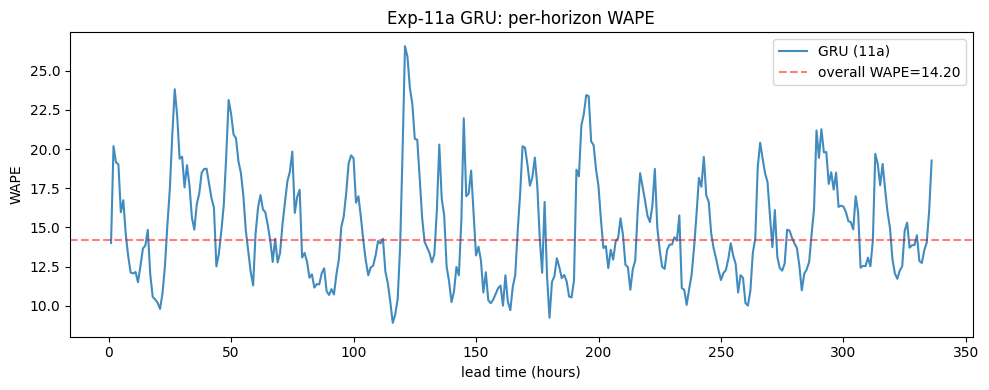

In [11]:
BINS = [(1, 1), (2, 6), (7, 24), (25, 72), (73, 168), (169, 336)]

print(f"{'lead-h range':>14}  {'count':>8}  {'WAPE GRU':>10}")
print("-" * 40)
for lo, hi in BINS:
    mask = (oof_df["lead_h"] >= lo) & (oof_df["lead_h"] <= hi)
    sub  = oof_df[mask]
    w    = wape(sub["target"], sub["pred_gru"])
    label = f"{lo:>3}..{hi:<3}h"
    print(f"  {label:>12}  {len(sub):>8d}    {w:>7.3f}")

# Per-lead plot
per_lead = oof_df.groupby("lead_h").apply(
    lambda g: pd.Series({"wape_gru": wape(g["target"], g["pred_gru"])})
).reset_index()

plt.figure(figsize=(10, 4))
plt.plot(per_lead["lead_h"], per_lead["wape_gru"], lw=1.5, label="GRU (11a)", alpha=0.85)
plt.axhline(GRU_WAPE, ls="--", color="red", alpha=0.5, label=f"overall WAPE={GRU_WAPE:.2f}")
plt.xlabel("lead time (hours)")
plt.ylabel("WAPE")
plt.title("Exp-11a GRU: per-horizon WAPE")
plt.legend()
plt.tight_layout()
plt.show()

---
## §10. Per-Series WAPE

Checks whether hard-series oversampling moved the worst-20 series.

In [12]:
per_series = oof_df.groupby("series_id").apply(
    lambda g: pd.Series({
        "wape_gru": wape(g["target"], g["pred_gru"]),
        "n_rows":   len(g),
    })
).reset_index().sort_values("wape_gru", ascending=False)

print(f"Per-series WAPE — worst 20:")
print(per_series.head(20).to_string(index=False))
print(f"\nBest 5:")
print(per_series.tail(5).to_string(index=False))
print(f"\nOverall: min={per_series['wape_gru'].min():.2f}, "
      f"max={per_series['wape_gru'].max():.2f}, "
      f"mean={per_series['wape_gru'].mean():.2f}")

Per-series WAPE — worst 20:
series_id  wape_gru  n_rows
 unit_073 25.135528  1008.0
 unit_058 21.278219  1008.0
 unit_056 20.921855  1008.0
 unit_066 20.778189  1008.0
 unit_071 19.589443  1008.0
 unit_079 19.000086  1008.0
 unit_003 18.918209  1008.0
 unit_039 18.667026  1008.0
 unit_022 18.554842  1008.0
 unit_028 18.013057  1008.0
 unit_011 17.878887  1008.0
 unit_063 17.786992  1008.0
 unit_009 17.541492  1008.0
 unit_040 17.539929  1008.0
 unit_025 17.496186  1008.0
 unit_031 17.441017  1008.0
 unit_061 17.375323  1008.0
 unit_094 17.357778  1008.0
 unit_087 17.302134  1008.0
 unit_080 17.271630  1008.0

Best 5:
series_id  wape_gru  n_rows
 unit_018  9.947054  1008.0
 unit_030  9.716320  1008.0
 unit_043  8.998162  1008.0
 unit_015  8.818395  1008.0
 unit_069  6.962017  1008.0

Overall: min=6.96, max=25.14, mean=14.42


---
## §11. Validation Predictions (for leaderboard submission)

Retrain on all training data (no fold holdout) with 5 seeds, encode the last 168h
before the validation window, decode the 336h future covariates from `validation_input.csv`.

In [ ]:
@torch.no_grad()
def predict_validation(model, feat_scaler, vel_scaler, mu, sd):
    """Generate validation predictions for all 96 series."""
    model.eval()
    lookback = ENCODER_LOOKBACK
    all_preds = []
    for s in range(N_SERIES):
        arr    = SERIES_ARR[s]
        cov_n  = feat_scaler.transform(arr["cov"])
        cov_n  = np.nan_to_num(cov_n, nan=0.0).astype(np.float32)
        vel_n  = vel_scaler.transform(arr["vel"])
        vel_n  = np.nan_to_num(vel_n, nan=0.0).astype(np.float32)
        tgt_n  = ((arr["tgt"] - mu[s]) / sd[s]).astype(np.float32)

        enc_s = T_PER_SERIES - lookback
        past_cov  = torch.from_numpy(cov_n[enc_s:]).unsqueeze(0).to(DEVICE)
        past_vel  = torch.from_numpy(vel_n[enc_s:]).unsqueeze(0).to(DEVICE)
        past_tgt  = torch.from_numpy(tgt_n[enc_s:]).unsqueeze(0).to(DEVICE)
        past_time = torch.from_numpy(arr["time"][enc_s:].astype(np.float32)).unsqueeze(0).to(DEVICE)

        val = VAL_ARR[s]
        fut_cov_n = feat_scaler.transform(val["cov"]).astype(np.float32)
        fut_cov_n = np.nan_to_num(fut_cov_n, nan=0.0)
        fut_vel_n = vel_scaler.transform(val["vel"]).astype(np.float32)
        fut_vel_n = np.nan_to_num(fut_vel_n, nan=0.0)

        fut_cov  = torch.from_numpy(fut_cov_n).unsqueeze(0).to(DEVICE)
        fut_vel  = torch.from_numpy(fut_vel_n).unsqueeze(0).to(DEVICE)
        fut_time = torch.from_numpy(val["time"].astype(np.float32)).unsqueeze(0).to(DEVICE)
        sid_t    = torch.tensor([s], dtype=torch.long, device=DEVICE)

        pred_norm = model(past_cov, past_vel, past_tgt, past_time, fut_cov, fut_vel, fut_time, sid_t)
        pred_orig = pred_norm.cpu().numpy()[0] * sd[s] + mu[s]
        all_preds.append(pred_orig)
    return np.stack(all_preds)  # (96, H)


print("Training final model on all data (5 seeds)...")
# Normalizers fit on all training data
all_cov = np.concatenate([SERIES_ARR[s]["cov"] for s in range(N_SERIES)])
all_vel = np.concatenate([SERIES_ARR[s]["vel"] for s in range(N_SERIES)])
feat_s_full = RobustScaler().fit(all_cov)
vel_s_full  = RobustScaler().fit(all_vel)
mu_full = np.array([SERIES_ARR[s]["tgt"].mean() for s in range(N_SERIES)], dtype=np.float32)
sd_full = np.array([max(float(SERIES_ARR[s]["tgt"].std()), 1e-3) for s in range(N_SERIES)], dtype=np.float32)

# end_idx_override=T_PER_SERIES: train on ALL data (windows up to start=3648, decoder target up to 4320)
# This is the critical fix — fold_k=0 alone only exposes hours 0..3312 to the model.
FINAL_END_IDX = T_PER_SERIES

val_seed_preds = []
for seed in SEQ_SEEDS:
    torch.manual_seed(seed)
    np.random.seed(seed)
    ds_full = Seq2SeqDataset(
        fold_k=0,
        feat_scaler=feat_s_full, vel_scaler=vel_s_full,
        mu=mu_full, sd=sd_full,
        use_aug=USE_AUG, crop_lo=CROP_LOOKBACK_LO, crop_hi=CROP_LOOKBACK_HI,
        feat_drop_p=FEAT_DROP_P if USE_AUG else 0.0,
        oversample_factor=HARD_SERIES_OVS if USE_AUG else 1,
        end_idx_override=FINAL_END_IDX,
    )
    loader_full = DataLoader(
        ds_full, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=N_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(N_WORKERS > 0),
    )
    model_final = make_model()
    try:
        model_final = torch.compile(model_final)
    except Exception:
        pass
    opt_f = torch.optim.AdamW(model_final.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch_f = torch.optim.lr_scheduler.CosineAnnealingLR(opt_f, T_max=N_EPOCHS, eta_min=LR_MIN)
    amp_f = torch.cuda.amp.GradScaler() if DEVICE.type == "cuda" else None
    for ep in range(N_EPOCHS):
        train_one_epoch(model_final, loader_full, opt_f, amp_f)
        sch_f.step()
    vp = predict_validation(model_final, feat_s_full, vel_s_full, mu_full, sd_full)
    val_seed_preds.append(vp)
    print(f"  seed {seed} done")

val_avg = np.stack(val_seed_preds).mean(axis=0)  # (96, H)

# Build submission CSV
val_rows = []
for s in range(N_SERIES):
    sid_str = code_to_sid[s]
    for h in range(EVAL_HORIZON):
        val_rows.append({
            "series_id":  sid_str,
            "timestamp":  VAL_ARR[s]["ts"][h],
            "prediction": float(val_avg[s, h]),
        })
val_sub = pd.DataFrame(val_rows)
val_sub.to_csv(VAL_OUT, index=False)
print(f"Validation predictions saved to {VAL_OUT}")
print(f"Shape: {val_sub.shape}")

Training final model on all data (5 seeds)...


---
## §12. Summary

Report the key numbers for the README.

In [ ]:
print("=" * 50)
print("Experiment 11a — GRU Encoder-Decoder Summary")
print("=" * 50)
print(f"Best ablation config : {best_cfg_name}")
print(f"  use_aug            : {USE_AUG}")
print(f"  use_velocity       : {USE_VELOCITY}")
print()
print(f"CV WAPE per fold     : {[f'{w:.3f}' for w in gru_arr]}")
print(f"CV WAPE mean ± std   : {GRU_WAPE:.3f} ± {GRU_STD:.3f}")
if 'r_overall' in dir():
    print(f"Residual r vs 7c     : {r_overall:.4f}")
print()
print("Ablation results:")
print(abl_df.to_string(index=False))